In [ ]:
!pip install -q roboflow

from roboflow import Roboflow

rf = Roboflow(api_key="aNXc2kSHxbeUZKR6t6dQ")
project = rf.workspace("rajas-workspace-fhlm5").project(
    "pkr-5000-verification"
)
version = project.version(5)
dataset = version.download("folder")

print("Dataset location:", dataset.location)

loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to PKR-5000-Verification-5 in folder:: 100%|██████████| 1949/1949 [00:00<00:00, 6347.97it/s]

Dataset location: /content/PKR-5000-Verification-5


In [ ]:
import os

data_dir = dataset.location

for root, dirs, files in os.walk(data_dir):
    level = root.replace(data_dir, "").count(os.sep)
    if level <= 3:
        print(
            "  " * level
            + os.path.basename(root)
            + f" ({len(files)} files)"
        )

PKR-5000-Verification-5 (2 files)
  train (0 files)
    genuine (888 files)
    counterfeit (716 files)
  test (0 files)
    genuine (61 files)
    counterfeit (53 files)
  valid (0 files)
    genuine (124 files)
    counterfeit (105 files)


In [ ]:
!pip install -q torch torchvision scikit-learn matplotlib seaborn

In [ ]:
import os
import copy
import random
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from torchvision.models import mobilenet_v3_large, MobileNet_V3_Large_Weights

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

# Uses the location returned by your Roboflow download code
data_dir = dataset.location

train_dir = os.path.join(data_dir, "train")
valid_dir = os.path.join(data_dir, "valid")
test_dir  = os.path.join(data_dir, "test")

for path in [train_dir, valid_dir, test_dir]:
    assert os.path.isdir(path), f"Folder not found: {path}"

# MobileNetV3 pretrained weights use ImageNet normalization
weights = MobileNet_V3_Large_Weights.DEFAULT

train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=5),
    transforms.ColorJitter(
        brightness=0.10, contrast=0.10
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

train_ds = datasets.ImageFolder(train_dir, transform=train_transform)
valid_ds = datasets.ImageFolder(valid_dir, transform=eval_transform)
test_ds  = datasets.ImageFolder(test_dir, transform=eval_transform)

print("Class mapping:", train_ds.class_to_idx)
print("Training images:", len(train_ds))
print("Validation images:", len(valid_ds))
print("Test images:", len(test_ds))

assert train_ds.class_to_idx == valid_ds.class_to_idx
assert train_ds.class_to_idx == test_ds.class_to_idx
assert len(train_ds.classes) == 2, "Expected exactly two classes."

train_loader = DataLoader(
    train_ds, batch_size=32, shuffle=True,
    num_workers=2, pin_memory=torch.cuda.is_available()
)
valid_loader = DataLoader(
    valid_ds, batch_size=32, shuffle=False,
    num_workers=2, pin_memory=torch.cuda.is_available()
)
test_loader = DataLoader(
    test_ds, batch_size=32, shuffle=False,
    num_workers=2, pin_memory=torch.cuda.is_available()
)

print("Ready for training.")

Device: cpu
Class mapping: {'counterfeit': 0, 'genuine': 1}
Training images: 1604
Validation images: 229
Test images: 114
Ready for training.


In [ ]:
model = mobilenet_v3_large(weights=weights)

# Freeze the feature extractor for the first training stage
for param in model.features.parameters():
    param.requires_grad = False

# Replace the original ImageNet classifier with two outputs
num_features = model.classifier[-1].in_features
model.classifier[-1] = nn.Linear(num_features, 2)

model = model.to(device)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(
    model.classifier.parameters(),
    lr=1e-3,
    weight_decay=1e-4
)

print(model.classifier)

Downloading: "https://download.pytorch.org/models/mobilenet_v3_large-5c1a4163.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v3_large-5c1a4163.pth


100%|██████████| 21.1M/21.1M [00:00<00:00, 40.6MB/s]


Sequential(
  (0): Linear(in_features=960, out_features=1280, bias=True)
  (1): Hardswish()
  (2): Dropout(p=0.2, inplace=True)
  (3): Linear(in_features=1280, out_features=2, bias=True)
)


In [ ]:
from sklearn.metrics import accuracy_score

EPOCHS = 12
best_val_acc = 0.0
best_state = copy.deepcopy(model.state_dict())
history = {"train_loss": [], "val_loss": [],
           "train_acc": [], "val_acc": []}

for epoch in range(EPOCHS):
    # Training
    model.train()
    train_loss_sum = 0.0
    train_correct = 0
    train_total = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        train_loss_sum += loss.item() * images.size(0)
        train_correct += (outputs.argmax(1) == labels).sum().item()
        train_total += labels.size(0)

    train_loss = train_loss_sum / train_total
    train_acc = train_correct / train_total

    # Validation
    model.eval()
    val_loss_sum = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in valid_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            val_loss_sum += loss.item() * images.size(0)
            val_correct += (outputs.argmax(1) == labels).sum().item()
            val_total += labels.size(0)

    val_loss = val_loss_sum / val_total
    val_acc = val_correct / val_total

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["train_acc"].append(train_acc)
    history["val_acc"].append(val_acc)

    if val_acc > best_val_acc:
        best_val_acc = val_acc
        best_state = copy.deepcopy(model.state_dict())

    print(
        f"Epoch {epoch+1:02d}/{EPOCHS} | "
        f"Train loss: {train_loss:.4f} | "
        f"Train acc: {train_acc:.3%} | "
        f"Val loss: {val_loss:.4f} | "
        f"Val acc: {val_acc:.3%}"
    )

model.load_state_dict(best_state)
print(f"\nBest validation accuracy: {best_val_acc:.3%}")

Epoch 01/12 | Train loss: 0.3837 | Train acc: 82.855% | Val loss: 0.4968 | Val acc: 77.729%
Epoch 02/12 | Train loss: 0.2819 | Train acc: 88.466% | Val loss: 0.3471 | Val acc: 84.716%
Epoch 03/12 | Train loss: 0.2416 | Train acc: 90.274% | Val loss: 0.3135 | Val acc: 84.716%
Epoch 04/12 | Train loss: 0.2263 | Train acc: 90.835% | Val loss: 0.3099 | Val acc: 87.773%
Epoch 05/12 | Train loss: 0.2072 | Train acc: 91.459% | Val loss: 0.3646 | Val acc: 83.406%
Epoch 06/12 | Train loss: 0.1833 | Train acc: 92.269% | Val loss: 0.3240 | Val acc: 86.900%
Epoch 07/12 | Train loss: 0.1555 | Train acc: 94.264% | Val loss: 0.3138 | Val acc: 87.773%
Epoch 08/12 | Train loss: 0.1355 | Train acc: 94.389% | Val loss: 0.3360 | Val acc: 86.026%
Epoch 09/12 | Train loss: 0.1249 | Train acc: 94.888% | Val loss: 0.3532 | Val acc: 86.900%
Epoch 10/12 | Train loss: 0.1232 | Train acc: 94.950% | Val loss: 0.3477 | Val acc: 86.026%
Epoch 11/12 | Train loss: 0.1254 | Train acc: 95.574% | Val loss: 0.3478 | Val a

Classes: ['counterfeit', 'genuine']

Classification report:
              precision    recall  f1-score   support

 counterfeit       0.86      0.96      0.91        53
     genuine       0.96      0.87      0.91        61

    accuracy                           0.91       114
   macro avg       0.91      0.92      0.91       114
weighted avg       0.92      0.91      0.91       114



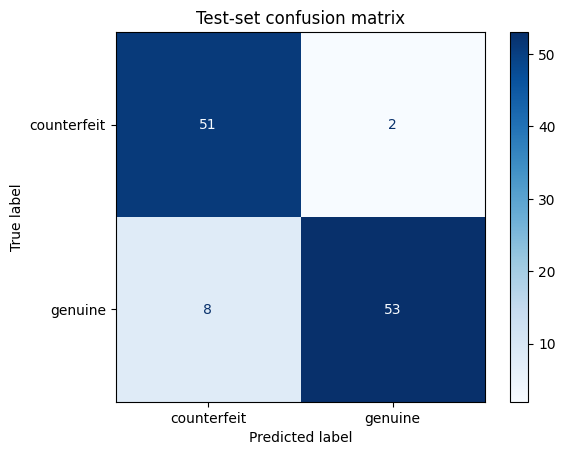

In [ ]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

model.eval()
all_preds = []
all_labels = []
all_probs = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        outputs = model(images)

        probs = torch.softmax(outputs, dim=1)
        preds = outputs.argmax(dim=1)

        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.numpy())
        all_probs.extend(probs.cpu().numpy())

class_names = test_ds.classes

print("Classes:", class_names)
print("\nClassification report:")
print(classification_report(
    all_labels,
    all_preds,
    labels=list(range(len(class_names))),
    target_names=class_names,
    zero_division=0
))

cm = confusion_matrix(
    all_labels,
    all_preds,
    labels=list(range(len(class_names)))
)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
).plot(cmap="Blues", values_format="d")

plt.title("Test-set confusion matrix")
plt.show()

In [ ]:
model_path = "/content/mobilenetv3_pkr5000.pth"

torch.save({
    "model_state_dict": model.state_dict(),
    "class_to_idx": train_ds.class_to_idx,
    "class_names": train_ds.classes,
    "image_size": 224
}, model_path)

print("Saved model to:", model_path)

Saved model to: /content/mobilenetv3_pkr5000.pth


In [ ]:
from google.colab import files
files.download(model_path)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Test images: 114
Test accuracy: 91.23%

Classification report:
              precision    recall  f1-score   support

 counterfeit     0.8644    0.9623    0.9107        53
     genuine     0.9636    0.8689    0.9138        61

    accuracy                         0.9123       114
   macro avg     0.9140    0.9156    0.9123       114
weighted avg     0.9175    0.9123    0.9124       114



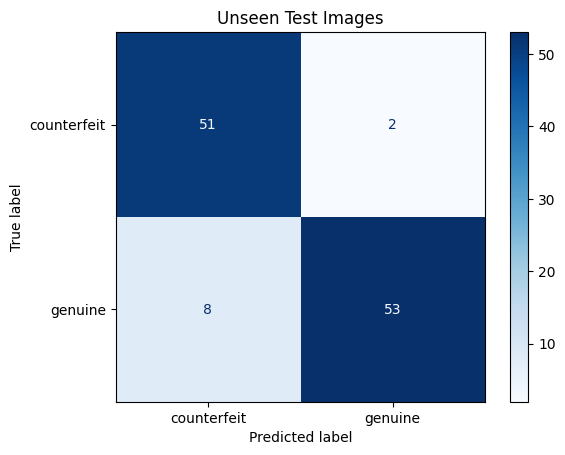


Misclassified images:
Actual: counterfeit | Predicted: genuine | Confidence: 61.4% | File: /content/PKR-5000-Verification-5/test/counterfeit/ds2_346_IMG20220218162850_jpg.rf.87520388bdf79996585aeff97b9f5449.jpg
Actual: counterfeit | Predicted: genuine | Confidence: 56.9% | File: /content/PKR-5000-Verification-5/test/counterfeit/ds2_676_IMG20220209121737_jpg.rf.a32d787dfd8bdc02f0a3aa8dac902e72.jpg
Actual: genuine | Predicted: counterfeit | Confidence: 64.0% | File: /content/PKR-5000-Verification-5/test/genuine/Real-Notes-450-_jpg.rf.353b0e6721a32955c0d8a9b5a171b6f4.jpg
Actual: genuine | Predicted: counterfeit | Confidence: 67.1% | File: /content/PKR-5000-Verification-5/test/genuine/Real-Notes-473-_jpg.rf.93109f9ed6a09684995a3dff9cd0103e.jpg
Actual: genuine | Predicted: counterfeit | Confidence: 71.4% | File: /content/PKR-5000-Verification-5/test/genuine/WhatsApp-Image-2026-08-09-at-07-20-20-1-_jpeg.rf.8d80f3a3b350ee9e45776d1e62d524d5.jpg
Actual: genuine | Predicted: counterfeit | Confi

In [ ]:
import torch
import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    accuracy_score
)
from torch.utils.data import DataLoader
from torchvision import transforms, datasets

# Use the same preprocessing as validation
device = next(model.parameters()).device
model.eval()

# Ensure evaluation uses deterministic preprocessing
eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

test_ds = datasets.ImageFolder(
    test_dir,
    transform=eval_transform
)

test_loader = DataLoader(
    test_ds,
    batch_size=32,
    shuffle=False,
    num_workers=2
)

class_names = test_ds.classes
all_labels, all_preds, all_probs = [], [], []

with torch.inference_mode():
    for images, labels in test_loader:
        images = images.to(device)
        logits = model(images)
        probs = torch.softmax(logits, dim=1)
        preds = logits.argmax(dim=1)

        all_labels.extend(labels.numpy().tolist())
        all_preds.extend(preds.cpu().numpy().tolist())
        all_probs.extend(probs.cpu().numpy().tolist())

# Overall accuracy
accuracy = accuracy_score(all_labels, all_preds)
print(f"Test images: {len(test_ds)}")
print(f"Test accuracy: {accuracy:.2%}")

# Per-class precision, recall and F1-score
print("\nClassification report:")
print(classification_report(
    all_labels,
    all_preds,
    labels=list(range(len(class_names))),
    target_names=class_names,
    zero_division=0,
    digits=4
))

# Confusion matrix
cm = confusion_matrix(
    all_labels,
    all_preds,
    labels=list(range(len(class_names)))
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)
disp.plot(cmap="Blues", values_format="d")
plt.title("Unseen Test Images")
plt.show()

# List misclassified images
print("\nMisclassified images:")
mistakes = []

for i, (true_idx, pred_idx) in enumerate(
    zip(all_labels, all_preds)
):
    if true_idx != pred_idx:
        path, _ = test_ds.samples[i]
        confidence = max(all_probs[i])

        mistakes.append({
            "file": path,
            "actual": class_names[true_idx],
            "predicted": class_names[pred_idx],
            "confidence": confidence
        })

for item in mistakes:
    print(
        f"Actual: {item['actual']} | "
        f"Predicted: {item['predicted']} | "
        f"Confidence: {item['confidence']:.1%} | "
        f"File: {item['file']}"
    )

print(f"\nTotal mistakes: {len(mistakes)}")

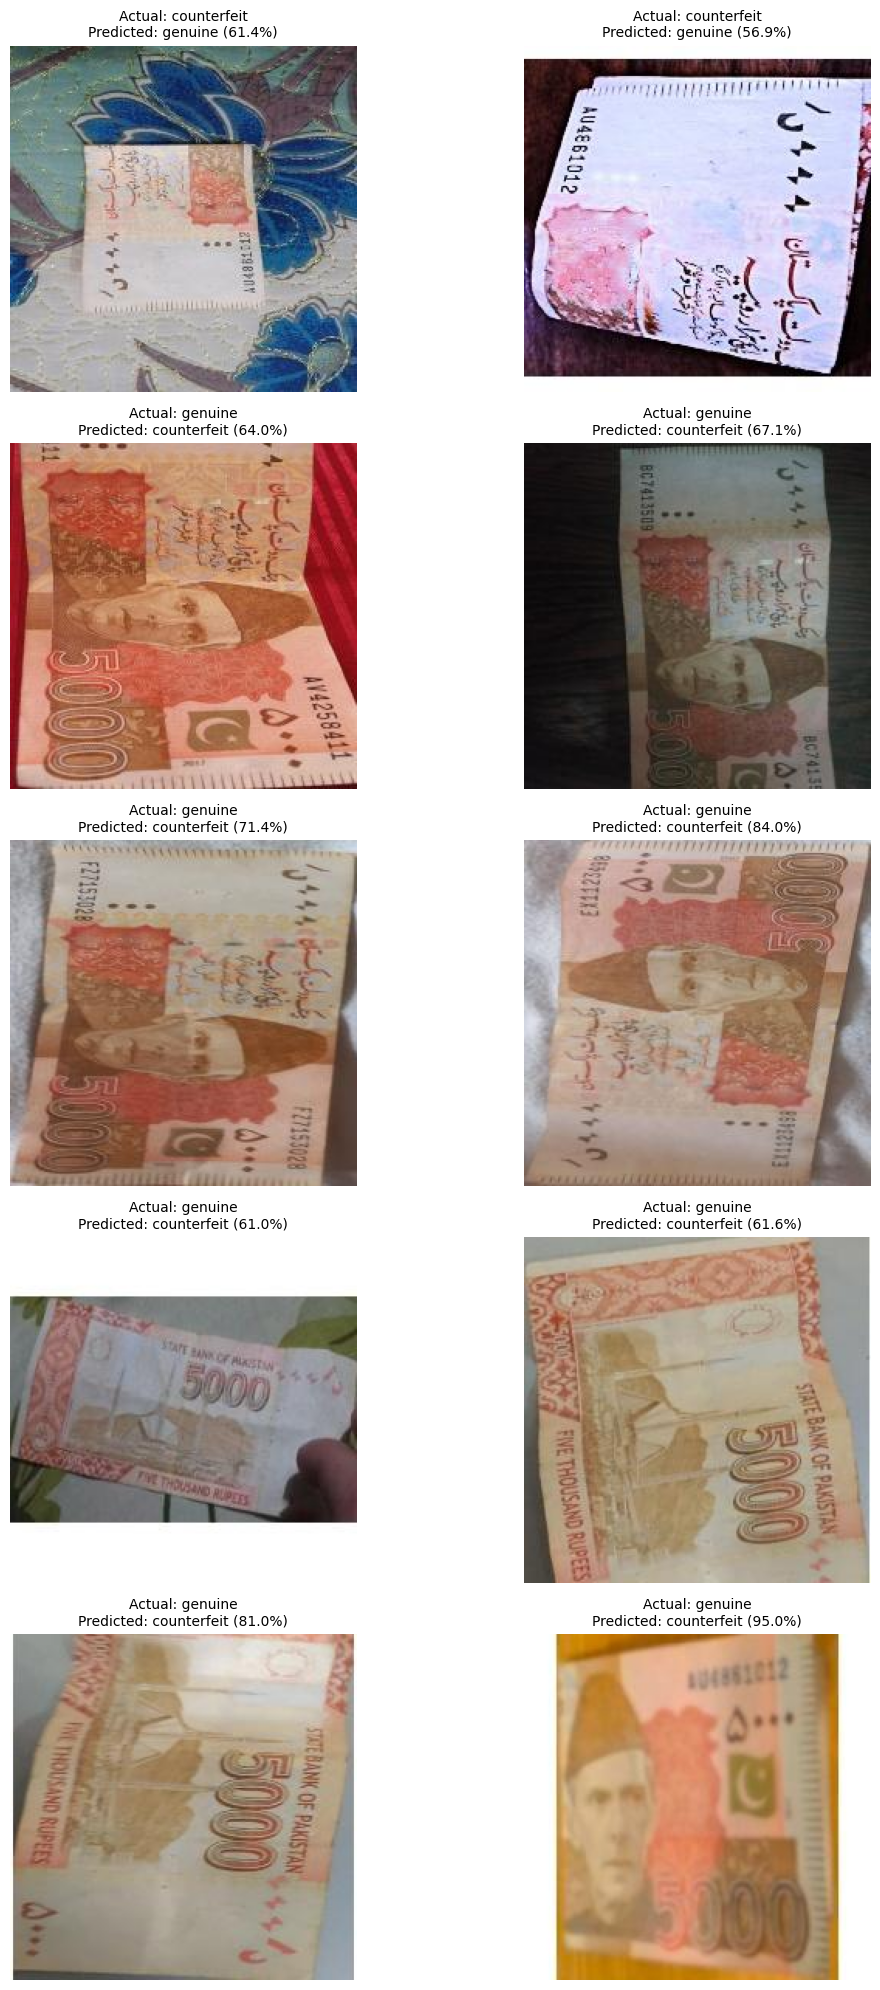

In [ ]:
import matplotlib.pyplot as plt
from PIL import Image

mistakes = [
    i for i, (actual, predicted)
    in enumerate(zip(all_labels, all_preds))
    if actual != predicted
]

if not mistakes:
    print("No misclassified images found.")
else:
    cols = 2
    rows = (len(mistakes) + cols - 1) // cols

    fig, axes = plt.subplots(
        rows, cols, figsize=(12, rows * 4)
    )
    axes = np.array(axes).reshape(-1)

    for ax, idx in zip(axes, mistakes):
        path, actual_idx = test_ds.samples[idx]
        image = Image.open(path).convert("RGB")

        predicted_idx = all_preds[idx]
        confidence = max(all_probs[idx]) * 100

        ax.imshow(image)
        ax.set_title(
            f"Actual: {class_names[actual_idx]}\n"
            f"Predicted: {class_names[predicted_idx]} "
            f"({confidence:.1f}%)",
            fontsize=10
        )
        ax.axis("off")

    for ax in axes[len(mistakes):]:
        ax.axis("off")

    plt.tight_layout()
    plt.show()

Saving IMG-20261022-WA0019(26).jpg to IMG-20261022-WA0019(26).jpg


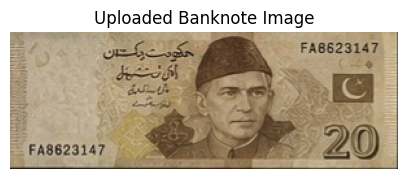

MODEL PREDICTION
Predicted class: counterfeit
Model confidence: 99.83%

Class probabilities:
counterfeit: 99.83%
genuine: 0.17%

Note: This is a model prediction, not proof of banknote authenticity.


In [ ]:
from google.colab import files
from PIL import Image
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
from torchvision import transforms
import io

# Upload an image from your computer
uploaded = files.upload()

# Use the first uploaded image
filename = next(iter(uploaded))
image = Image.open(io.BytesIO(uploaded[filename])).convert("RGB")

# Display the image
plt.figure(figsize=(5, 5))
plt.imshow(image)
plt.axis("off")
plt.title("Uploaded Banknote Image")
plt.show()

# Preprocess exactly as used during validation
preprocess = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

input_tensor = preprocess(image).unsqueeze(0).to(device)

# Predict
model.eval()
with torch.no_grad():
    outputs = model(input_tensor)
    probabilities = F.softmax(outputs, dim=1)[0]

# Use the class mapping learned from your dataset
class_names = test_ds.classes
predicted_idx = probabilities.argmax().item()
predicted_class = class_names[predicted_idx]
confidence = probabilities[predicted_idx].item() * 100

print("=" * 40)
print("MODEL PREDICTION")
print("=" * 40)
print(f"Predicted class: {predicted_class}")
print(f"Model confidence: {confidence:.2f}%")
print("\nClass probabilities:")

for i, name in enumerate(class_names):
    print(f"{name}: {probabilities[i].item() * 100:.2f}%")

print("\nNote: This is a model prediction, not proof of banknote authenticity.")

In [ ]:
import copy
import torch
import torch.nn as nn

device = next(model.parameters()).device

# Unfreeze the later feature blocks.
# MobileNetV3-Large has feature blocks indexed 0 through 16.
for param in model.features.parameters():
    param.requires_grad = False

for param in model.features[12:].parameters():
    param.requires_grad = True

# Train the classifier as well.
for param in model.classifier.parameters():
    param.requires_grad = True

model = model.to(device)

# Lower learning rates help preserve pretrained features.
optimizer = torch.optim.AdamW(
    [
        {
            "params": model.features[12:].parameters(),
            "lr": 1e-5
        },
        {
            "params": model.classifier.parameters(),
            "lr": 1e-4
        }
    ],
    weight_decay=1e-4
)

criterion = nn.CrossEntropyLoss()

print("Fine-tuning setup complete.")
print("Device:", device)

Fine-tuning setup complete.
Device: cpu


In [ ]:
from copy import deepcopy
import numpy as np

FINE_TUNE_EPOCHS = 10

# Save the current model as the starting checkpoint.
best_state = deepcopy(model.state_dict())
best_val_loss = float("inf")
epochs_without_improvement = 0
patience = 3

fine_history = {
    "train_loss": [],
    "val_loss": [],
    "train_acc": [],
    "val_acc": []
}

for epoch in range(FINE_TUNE_EPOCHS):
    # ----- Training -----
    model.train()
    train_loss_sum = 0.0
    train_correct = 0
    train_total = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad(set_to_none=True)

        logits = model(images)
        loss = criterion(logits, labels)

        loss.backward()
        optimizer.step()

        train_loss_sum += loss.item() * labels.size(0)
        train_correct += (logits.argmax(1) == labels).sum().item()
        train_total += labels.size(0)

    train_loss = train_loss_sum / train_total
    train_acc = train_correct / train_total

    # ----- Validation -----
    model.eval()
    val_loss_sum = 0.0
    val_correct = 0
    val_total = 0

    with torch.inference_mode():
        for images, labels in valid_loader:
            images = images.to(device)
            labels = labels.to(device)

            logits = model(images)
            loss = criterion(logits, labels)

            val_loss_sum += loss.item() * labels.size(0)
            val_correct += (logits.argmax(1) == labels).sum().item()
            val_total += labels.size(0)

    val_loss = val_loss_sum / val_total
    val_acc = val_correct / val_total

    fine_history["train_loss"].append(train_loss)
    fine_history["val_loss"].append(val_loss)
    fine_history["train_acc"].append(train_acc)
    fine_history["val_acc"].append(val_acc)

    print(
        f"Epoch {epoch+1}/{FINE_TUNE_EPOCHS} | "
        f"Train loss: {train_loss:.4f} | "
        f"Train acc: {train_acc:.2%} | "
        f"Val loss: {val_loss:.4f} | "
        f"Val acc: {val_acc:.2%}"
    )

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_state = deepcopy(model.state_dict())
        epochs_without_improvement = 0

        torch.save({
            "model_state_dict": best_state,
            "class_to_idx": train_ds.class_to_idx,
            "class_names": train_ds.classes,
            "image_size": 224
        }, "/content/mobilenetv3_pkr5000_finetuned.pth")

        print("  Saved new best validation checkpoint.")
    else:
        epochs_without_improvement += 1

    if epochs_without_improvement >= patience:
        print("Early stopping: validation loss did not improve.")
        break

# Restore the best validation checkpoint.
model.load_state_dict(best_state)
model.eval()

print(f"\nBest validation loss: {best_val_loss:.4f}")
print("Best fine-tuned model restored.")

Epoch 1/10 | Train loss: 0.1823 | Train acc: 92.39% | Val loss: 0.3074 | Val acc: 86.03%
  Saved new best validation checkpoint.
Epoch 2/10 | Train loss: 0.1503 | Train acc: 94.58% | Val loss: 0.3022 | Val acc: 86.03%
  Saved new best validation checkpoint.
Epoch 3/10 | Train loss: 0.1422 | Train acc: 94.64% | Val loss: 0.3051 | Val acc: 86.46%
Epoch 4/10 | Train loss: 0.1362 | Train acc: 94.76% | Val loss: 0.2870 | Val acc: 86.90%
  Saved new best validation checkpoint.
Epoch 5/10 | Train loss: 0.1189 | Train acc: 95.45% | Val loss: 0.2862 | Val acc: 86.46%
  Saved new best validation checkpoint.
Epoch 6/10 | Train loss: 0.1088 | Train acc: 95.82% | Val loss: 0.2885 | Val acc: 86.46%
Epoch 7/10 | Train loss: 0.1036 | Train acc: 96.26% | Val loss: 0.3038 | Val acc: 86.46%
Epoch 8/10 | Train loss: 0.0977 | Train acc: 96.63% | Val loss: 0.2937 | Val acc: 86.90%
Early stopping: validation loss did not improve.

Best validation loss: 0.2862
Best fine-tuned model restored.
